# 02 · Manifold — principal-curve trajectory (non-branching)

The malignant manifold is a single low-aspect body: a PPT **tree** over-fits it
(spurious forks weaving through a filled cloud), so the topology is fit with an
ElPiGraph principal **curve** (scFates `curve`) and verified fold-free. Root at
the **developmental origin** derived from the signatures (Gast/pSom-high,
Crest-low, low-cycling tip — never the proliferation edge), compute pseudotime,
and confirm the axis is not proliferation-driven. Deliverable: `manifold.h5ad`,
`manifold.pdf`.

In [ ]:
import os, sys, glob, io, contextlib, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold; re-score modules on the joint embedding
The whole malignant compartment (one low-cycling body) is the trajectory object.

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP principal-axis ratio (major/minor singular value): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]
print('raw module means (honest readout):',
      adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

whole malignant manifold: 22599 cells on the joint embedding
UMAP principal-axis ratio (major/minor singular value): 1.58
Gast: 64/81 genes present
pSom: 77/98 genes present
Crest: 88/104 genes present
raw module means (honest readout): {'Gast': -0.027, 'pSom': 0.0016, 'Crest': 0.0051}


### Module cross-repression + cell-cycle confounder check
Smoothed spatial correlations of the modules, and how much each module overlaps
the cell-cycle programme (so proliferation is not mistaken for a signature).

In [ ]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
g1s = pd.to_numeric(adata.obs['g1s_score'], errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'], errors='coerce').fillna(0).values
cyc = np.maximum(g1s, g2m)
print('module vs cycling score:')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {m}: r = {np.corrcoef(adata.obs[m], cyc)[0,1]:+.2f}')
print('cycling fraction: %.3f (single low-cycling body)' % adata.obs['cycling'].mean())
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = -0.41
  Crest_sm vs Gast_sm: r = -0.28
  Crest_sm vs pSom_sm: r = -0.52
module vs cycling score:
  Gast_sm: r = -0.59
  pSom_sm: r = +0.42
  Crest_sm: r = -0.12
cycling fraction: 0.107 (single low-cycling body)


### Topology: curve vs tree — pick the fold-free principal curve
Fit a principal curve across `Nodes ∈ {15,20,30}` and measure tips, forks, and a
fold self-approach ratio (min non-adjacent node distance / median edge length;
>1 = fold-free). Zero forks confirms the non-branching topology; a PPT tree on
this filled body would instead report multiple spurious forks.

In [ ]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

# contrast: a PPT tree over-fits this low-aspect body with spurious forks
at = sub.copy()
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.tree(at, method='ppt', Nodes=200, ppt_lambda=2000, ppt_sigma=0.5,
                use_rep='X_umap', seed=SEED, plot=False, basis='umap')
Bt = np.asarray(at.uns['graph']['B'])
print(f'PPT tree N=200: {int(((Bt>0).sum(0)>=3).sum())} forks (spurious on a filled body)')

for Nn in [15, 20, 30]:
    a2 = sub.copy()
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.curve(a2, Nodes=Nn, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
    sa, tips, forks = fold_diag(a2)
    print(f'curve N={Nn}: {tips} tips, {forks} forks | self-approach {sa:.2f}')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'chosen curve N=20: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

PPT tree N=200: 6 forks (spurious on a filled body)
curve N=15: 2 tips, 0 forks | self-approach 2.98
curve N=20: 2 tips, 0 forks | self-approach 2.95
curve N=30: 2 tips, 0 forks | self-approach 2.83
chosen curve N=20: 2 tips, 0 forks | fold self-approach ratio = 2.95 (>1 = fold-free)


### Root at the developmental origin (data-driven) + pseudotime
Score each curve tip by Gast+pSom−Crest and root at the maximum (the
Gast/pSom-high, Crest-low pole). Confirm the modules gradient along pseudotime
in developmental order and that the axis is not proliferation-driven.

In [ ]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(),
                sub.obs['Crest_sm'][m].mean(), cyc[m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f} cycling={info[tp][3]:.3f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low, low-cycling developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')
tn = (t-t.min())/(t.max()-t.min())
for m,lab_ in [('Crest_sm','Neural-crest'),('pSom_sm','Somitogenesis'),('Gast_sm','Gastrulation')]:
    hi = sub.obs[m] >= sub.obs[m].quantile(0.9)
    print(f'{lab_}-high decile mean pseudotime = {tn[hi.values].mean():.2f}')
rho_c,_ = spearmanr(t, cyc); print(f'caveat: pseudotime vs cycling score rho = {rho_c:+.2f} '
      '(low -> axis not proliferation-driven)')

tip 0: Gast=-0.0247 pSom=+0.0016 Crest=+0.0053 cycling=0.065
tip 2: Gast=-0.0330 pSom=+0.0035 Crest=+0.0065 cycling=0.697
derived root = tip 0 (Gast/pSom-high, Crest-low, low-cycling developmental origin)
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho=-0.772 p=0.0e+00
  pSom_sm: rho=-0.153 p=5.0e-118
  Crest_sm: rho=+0.274 p=0.0e+00
Neural-crest-high decile mean pseudotime = 0.77
Somitogenesis-high decile mean pseudotime = 0.75
Gastrulation-high decile mean pseudotime = 0.07
caveat: pseudotime vs cycling score rho = +0.29 (low -> axis not proliferation-driven)


### Orientation consistency (house linear layout re-used from 01)
Confirm the stored `X_umap_lin` orientation is pseudotime-consistent (origin on
the left), so 01–04 share one orientation.

In [ ]:
t = sub.obs['t'].values
r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])   # re-used from 01
c = sub.obsm['X_umap'] - sub.obsm['X_umap'].mean(0)
dirv = np.array([np.cov(c[:,0], t)[0,1], np.cov(c[:,1], t)[0,1]])
_, _, vt = np.linalg.svd(c, full_matrices=False)
dang = abs(np.degrees(np.arctan2(dirv[1],dirv[0]) - np.arctan2(vt[0,1],vt[0,0]))) % 180
dang = min(dang, 180-dang)
if r < 0:      # ensure origin on the left for this dataset's layout
    sub.obsm['X_umap_lin'][:,0] = -sub.obsm['X_umap_lin'][:,0]
    r = float(np.corrcoef(sub.obsm['X_umap_lin'][:,0], t)[0,1])
assert r > 0.5, f'stored orientation not pseudotime-consistent (corr={r:.2f})'
print(f'house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = {r:+.2f}')
print(f'variance-axis vs pseudotime-axis disagreement = {dang:.1f}deg (small -> equivalent orientation)')

house orientation re-used from 01 (X_umap_lin); corr(x_lin, pseudotime) = +0.99
variance-axis vs pseudotime-axis disagreement = 1.4deg (small -> equivalent orientation)


### Save manifold + pseudotime figure (deliverable)

saved manifold.h5ad + manifold.pdf


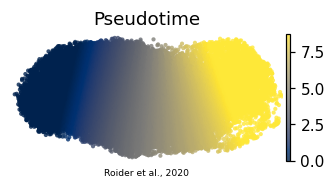

In [ ]:
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Roider et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')